In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import ast
import os



# matplotlib settings
# --- Publication style settings ---
plt.rcParams.update({
    # Font
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Times", "DejaVu Serif"],
    "mathtext.fontset": "stix",
    "text.usetex": False,

    # Editable, Affinity-compatible font embedding
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "svg.fonttype": "none",

    # Figure
    "figure.figsize": (6, 4),
    "figure.dpi": 150,

    # Axes
    "axes.titlesize": 12,
    "axes.labelsize": 10,
    "axes.linewidth": 1.2,
    "axes.grid": True,
    "grid.linestyle": "--",
    "grid.alpha": 0.7,

    # Ticks
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.top": True,
    "ytick.right": True,

    # Lines
    "lines.linewidth": 2,
    "lines.markersize": 6,

    # Legend
    "legend.fontsize": 10,
    "legend.frameon": False
})

# functions to calculate statistics
def RMSE(actual, predicted):
    
    # Convert inputs to numpy arrays 
    actual = np.array(actual)
    predicted = np.array(predicted)

    
    # Calculate the squared differences
    squared_diff = (actual - predicted) ** 2
    
    # Compute the mean of squared differences
    mean_squared_diff = np.mean(squared_diff)
    
    # Take the square root of the mean squared difference
    return np.sqrt(mean_squared_diff)

def find_xtc_filenames(path_to_dir, suffix=".xtc"):
    filenames = os.listdir(path_to_dir)
    return [filename for filename in filenames if filename.endswith(suffix)]

def compute_free_energy(Q, nbins=30, unfolded_cutoff=0.1, wopt=None):
    k = 0.008314
    T = 303.0
    kT = k * T

    
    if wopt is None:
        wopt = np.ones(Q.shape[0])/Q.shape[0]
        

    # Histograms
    def compute_FEL(Q, weights=None):
        counts, bins = np.histogram(Q, bins=nbins, weights=weights)
        centers = 0.5 * (bins[1:] + bins[:-1])
        p = counts / np.sum(counts)
        p[p <= 0] = np.nan
        fel = -np.log(p) * kT
        fel -= np.nanmin(fel)
        return centers, fel * 0.239005736

    centers_prior, fel_prior = compute_FEL(Q)
    centers_post, fel_post = compute_FEL(Q, weights=wopt)

    # Energetics 1: completely unfolded state relative to native state (comparable to what HDX probes)
    unfolded = np.where(Q < unfolded_cutoff)[0]
    # get cutoff for folded state from FEL
    min_Q_idx = np.where(fel_prior ==np.min(fel_prior))[0]
    minQ = centers_prior[min_Q_idx]
    native_cutoff = 0.7 * minQ
    folded = np.where(Q > native_cutoff)[0]

    dG_prior = -kT * np.log(len(folded) / len(unfolded)) * 0.239005736
    dG_post = -kT * np.log(np.sum(wopt[folded]) / np.sum(wopt[unfolded])) * 0.239005736

    # Energetics 2: native state relative to the rest (including potential intermediates, comparable to what cDNA proteolysis probes)
    # criteria: the main energy barrier between native and unfolded must be overcome --> cutoff decided as the max free energy between Q 0.2 and 0.8
    mask = (centers_prior > 0.2) & (centers_prior < 0.8)
    max_Q_idx = np.where(fel_prior ==np.max(fel_prior[mask]))[0][0]
    native_cutoff2 = centers_prior[max_Q_idx]
    folded = np.where(Q > native_cutoff2)[0]
    unfolded = np.where(Q < native_cutoff2)[0]

    dG_prior2 = -kT * np.log(len(folded) / len(unfolded)) * 0.239005736
    dG_post2 = -kT * np.log(np.sum(wopt[folded]) / np.sum(wopt[unfolded])) * 0.239005736

    return centers_prior, fel_prior, centers_post, fel_post, dG_prior, dG_post, dG_prior2, dG_post2, native_cutoff, native_cutoff2

def find_elbow(x, y):
    # Convert to numpy arrays
    x = np.array(x)
    y = np.array(y)

    # Sort x (and y) if needed, but keep track of original indices
    if not np.all(np.diff(x) >= 0):
        idx_sort = np.argsort(x)
        x_sorted = x[idx_sort]
        y_sorted = y[idx_sort]
    else:
        idx_sort = np.arange(len(x))
        x_sorted, y_sorted = x, y

    # Line between first and last point
    p1 = np.array([x_sorted[0], y_sorted[0]])
    p2 = np.array([x_sorted[-1], y_sorted[-1]])
    line_vec = p2 - p1
    line_vec_norm = line_vec / np.linalg.norm(line_vec)

    # Distances from each point to the line
    vec_from_p1 = np.vstack([x_sorted - p1[0], y_sorted - p1[1]]).T
    proj_len = np.dot(vec_from_p1, line_vec_norm)
    proj_point = np.outer(proj_len, line_vec_norm) + p1
    dist = np.linalg.norm(vec_from_p1 - (proj_point - p1), axis=1)

    # Elbow = point with maximum distance
    idx_elbow_sorted = np.argmax(dist)
    idx_elbow_original = idx_sort[idx_elbow_sorted]

    return idx_elbow_original, x[idx_elbow_original], y[idx_elbow_original]


proteins = ['Ubiquitin']
protein = proteins[0]
ensemble_master_dir = 'BIOEMU_DATA'
outdir = './plots_Ubq/'

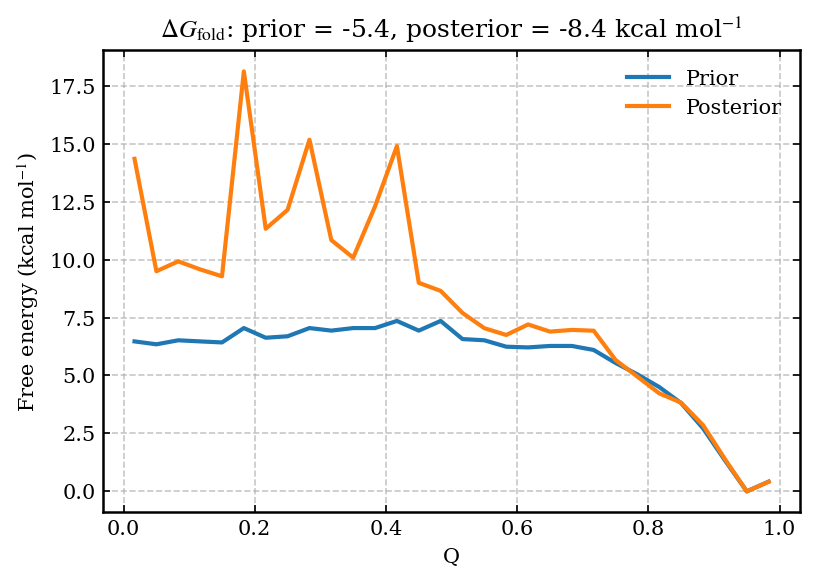

In [4]:
# free energy landscape of folding as a function of Q


nbins = 30

k = 0.008314
T = 303.0
kT = k*T

# get correct traj order
trajs = sorted(find_xtc_filenames(f'../../{ensemble_master_dir}/{protein}/'))

# cut-off for folding
unfolded_cutoff = 0.5

# load Q and frames data - fraction of native contacts
for i, traj in enumerate(trajs):
    if traj == trajs[0]:
        Q = np.loadtxt(f'../../{ensemble_master_dir}/{protein}/native_contacts/Q{traj[4:-4]}.txt')
        okframes = np.loadtxt(f'../../{ensemble_master_dir}/{protein}/rewM13DH_scaled/okframes_{traj[:-4]}.txt').astype(int)
        Q = Q[okframes]
    else:
        tmpQ = np.loadtxt(f'../../{ensemble_master_dir}/{protein}/native_contacts/Q{traj[4:-4]}.txt')
        okframes = np.loadtxt(f'../../{ensemble_master_dir}/{protein}/rewM13DH_scaled/okframes_{traj[:-4]}.txt').astype(int)
        Q = np.concatenate((Q, tmpQ[okframes]), axis=0)

w_prior = np.ones(len(Q))/len(Q)
w_post = np.load(f'../../{ensemble_master_dir}/{protein}/rewM14DH_scaled/log_lambda_wopt_elbow.npy')

# calculate folding free energies
folded = np.where(Q > unfolded_cutoff)[0]
unfolded = np.where(Q < unfolded_cutoff)[0]

dG_prior = -kT*np.log(np.sum(w_prior[folded])/np.sum(w_prior[unfolded]))*0.239005736
dG_post = -kT*np.log(np.sum(w_post[folded])/np.sum(w_post[unfolded]))*0.239005736

# use the same bin edges for prior and posterior
bin_edges = np.histogram_bin_edges(Q, bins=nbins)
bin_centers = (bin_edges[:-1] + bin_edges[1:])/2

counts_prior, _ = np.histogram(Q, bins=bin_edges, weights=w_prior)
counts_post, _ = np.histogram(Q, bins=bin_edges, weights=w_post)

p_prior = counts_prior/np.sum(counts_prior)
p_post = counts_post/np.sum(counts_post)

fel_prior = -np.log(p_prior)*kT
fel_post = -np.log(p_post)*kT

fel_prior = (fel_prior - np.nanmin(fel_prior))*0.239005736
fel_post = (fel_post - np.nanmin(fel_post))*0.239005736

plt.plot(bin_centers, fel_prior, label='Prior')
plt.plot(bin_centers, fel_post, label='Posterior')

plt.title(rf'$\Delta G_{{\mathrm{{fold}}}}$: prior = {dG_prior:.1f}, posterior = {dG_post:.1f} kcal mol$^{{-1}}$')
plt.xlabel('Q')
plt.ylabel(r'Free energy (kcal mol$^{-1}$)')
plt.legend()

-6.83
0.16
-5.452303586537737
-8.89796671141909
-8.548309308477773


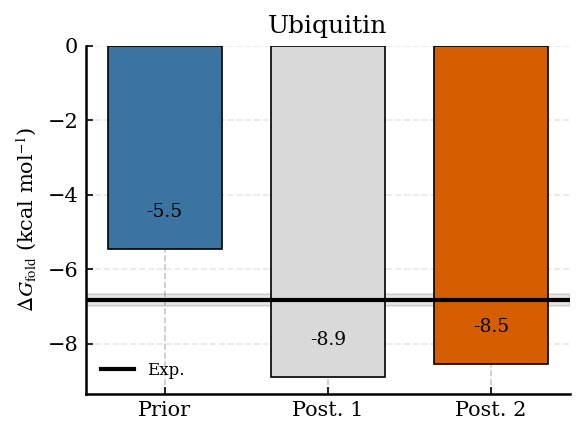

In [5]:
# barplot comparing experimental, prior, posterior 1, and posterior 2 folding free energies

protein = proteins[0]

COLOR3 = "#3B73A1"  # prior
COLOR2 = "#D9D9D9"  # posterior 1: elbow
COLOR1 = "#D55E00"  # posterior 2

# experimental dG
exp_dG, exp_dG_err = np.loadtxt(f'../../ORTHOGONAL_EXP_DATA/{protein}/dG.dat', unpack=True)

w_post1 = np.load(f'../../{ensemble_master_dir}/{protein}/rewM14DH_scaled/log_lambda_wopt_elbow.npy')
w_post2 = np.load(f'../../{ensemble_master_dir}/{protein}/rewM14DH_scaled/log_lambda_wopt.npy')
# prior + posterior 1 (elbow)
_, _, _, _, _, _, dG_prior, dG_post1, _, native_cutoff = compute_free_energy(Q=Q, wopt=w_post1)

# prior + posterior 2 (final)
_, _, _, _, _, _, _, dG_post2, _, native_cutoff = compute_free_energy(Q=Q, wopt=w_post2)

print(exp_dG)
print(exp_dG_err)
print(dG_prior)
print(dG_post1)
print(dG_post2)

labels = ['Prior', 'Post. 1', 'Post. 2']
values = [dG_prior, dG_post1, dG_post2]
colors = [COLOR3, COLOR2, COLOR1]
x = np.arange(len(labels))

fig, ax = plt.subplots(figsize=(4, 3))

bars = ax.bar(x, values, color=colors, edgecolor='black', linewidth=0.8, width=0.7, zorder=3)

# experimental value as black horizontal line
ax.axhline(exp_dG, color='black', lw=2, zorder=5, label='Exp.')

# optional experimental uncertainty band
ax.axhspan(exp_dG - exp_dG_err, exp_dG + exp_dG_err, color='black', alpha=0.10, zorder=1)

# value labels
for xi, yi in zip(x, values):
    ax.text(xi, yi + 0.08 * (ax.get_ylim()[1] - ax.get_ylim()[0] if ax.get_ylim()[1] > ax.get_ylim()[0] else 1), f'{yi:.1f}', ha='center', va='bottom', fontsize=9)

ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_ylabel(r'$\Delta G_{\mathrm{fold}}$ (kcal mol$^{-1}$)')
ax.set_title(protein)
ax.legend(frameon=False, fontsize=8, loc='best')

ax.tick_params(top=False, right=False)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.set_axisbelow(True)
ax.yaxis.grid(True, linestyle='--', alpha=0.3, zorder=0)

plt.tight_layout()
plt.savefig(outdir+f'{protein}_dG_barplot.pdf', dpi=300)
plt.show()

/tmp/ipykernel_418814/3282624701.py:47: RuntimeWarning: divide by zero encountered in log
  fel_prior = -np.log(p_prior)*kT
/tmp/ipykernel_418814/3282624701.py:48: RuntimeWarning: divide by zero encountered in log
  fel_post = -np.log(p_post)*kT


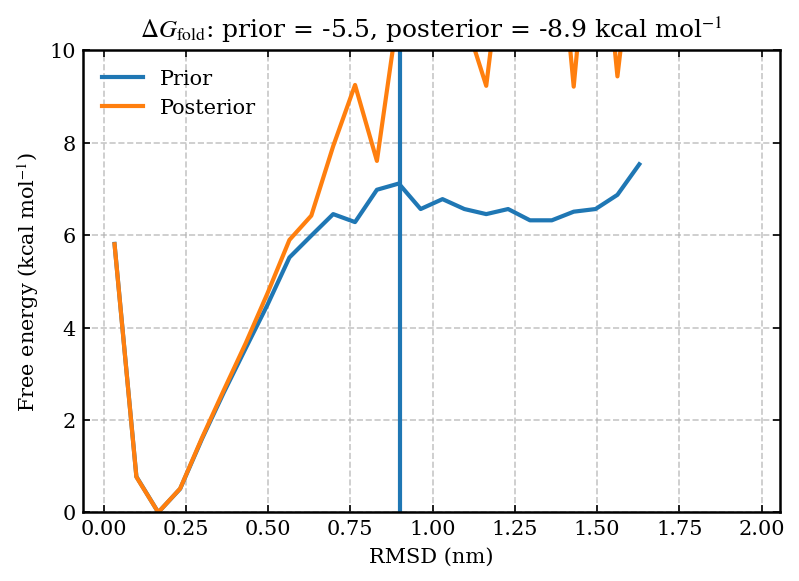

In [8]:
# free energy landscape of folding as a function of rmsd


nbins = 30

k = 0.008314
T = 303.0
kT = k*T

# get correct traj order
trajs = sorted(find_xtc_filenames(f'../../{ensemble_master_dir}/{protein}/'))

# cut-off for folding
folded_cutoff = 0.9

# load rmsd and frames data
for traj in trajs:
    if traj == trajs[0]:
        rmsd = np.loadtxt(f'../../{ensemble_master_dir}/{protein}/rmsd_data/rmsd_{traj}.xvg', skiprows=18)[:,1]
        okframes = np.loadtxt(f'../../{ensemble_master_dir}/{protein}/rewM13DH_scaled/okframes_{traj[:-4]}.txt').astype(int)
        rmsd = rmsd[okframes]
    else:
        tmprmsd = np.loadtxt(f'../../{ensemble_master_dir}/{protein}/rmsd_data/rmsd_{traj}.xvg', skiprows=18)[:,1]
        okframes = np.loadtxt(f'../../{ensemble_master_dir}/{protein}/rewM13DH_scaled/okframes_{traj[:-4]}.txt').astype(int)
        rmsd = np.concatenate((rmsd, tmprmsd[okframes]), axis=0)

w_prior = np.ones(len(rmsd))/len(rmsd)
w_post = np.load(f'../../{ensemble_master_dir}/{protein}/rewM14DH_scaled/log_lambda_wopt_elbow.npy')

# calculate folding free energies
folded = np.where(rmsd < folded_cutoff)[0]
unfolded = np.where(rmsd > folded_cutoff)[0]

dG_prior = -kT*np.log(np.sum(w_prior[folded])/np.sum(w_prior[unfolded]))*0.239005736
dG_post = -kT*np.log(np.sum(w_post[folded])/np.sum(w_post[unfolded]))*0.239005736

# use same bin edges for prior and posterior
bin_edges = np.histogram_bin_edges(rmsd, bins=nbins)
bin_centers = (bin_edges[:-1] + bin_edges[1:])/2

counts_prior, _ = np.histogram(rmsd, bins=bin_edges, weights=w_prior)
counts_post, _ = np.histogram(rmsd, bins=bin_edges, weights=w_post)

p_prior = counts_prior/np.sum(counts_prior)
p_post = counts_post/np.sum(counts_post)

fel_prior = -np.log(p_prior)*kT
fel_post = -np.log(p_post)*kT

fel_prior = (fel_prior - np.nanmin(fel_prior))*0.239005736
fel_post = (fel_post - np.nanmin(fel_post))*0.239005736

plt.plot(bin_centers, fel_prior, label='Prior')
plt.plot(bin_centers, fel_post, label='Posterior')
plt.ylim(0,10)
plt.axvline(0.9)

plt.title(rf'$\Delta G_{{\mathrm{{fold}}}}$: prior = {dG_prior:.1f}, posterior = {dG_post:.1f} kcal mol$^{{-1}}$')
plt.xlabel('RMSD (nm)')
plt.ylabel(r'Free energy (kcal mol$^{-1}$)')
plt.legend()

In [9]:
len(rmsd)

976718

/tmp/ipykernel_418814/3286864835.py:81: UserWarning: The following kwargs were not used by contour: 'rasterized'
  ax.contour(Xc, Yc, F_post, levels=levels, linewidths=0.8, colors='black', rasterized=True)


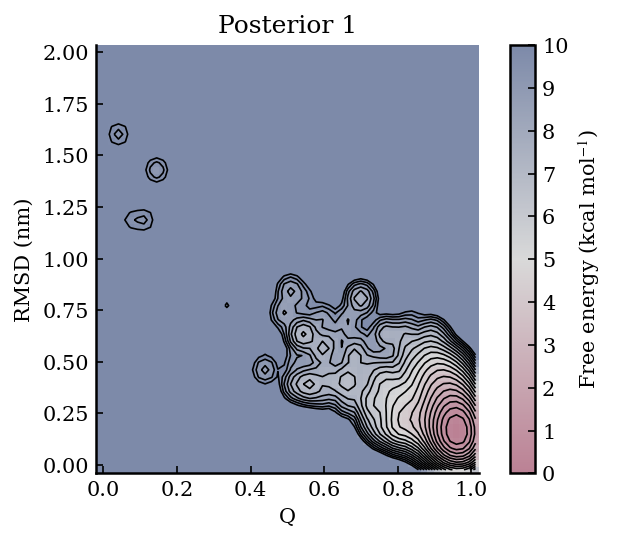

In [11]:
# FEL of posterior 1 (elbow) as a function of Q and RMSD
# with mild Gaussian smoothing of the 2D probability histogram

from matplotlib.colors import LinearSegmentedColormap
from scipy.ndimage import gaussian_filter


protein = proteins[0]
synframes = 0
nbins = 60
max_energy = 10.0   # kcal mol^-1; start with 5.0 or 6.0
sigma = 1.0     # Gaussian smoothing in bin units

# posterior 1 weights
wopt = np.load(f'../../{ensemble_master_dir}/{protein}/rewM14DH_scaled/log_lambda_wopt_elbow.npy')

# optional: drop synthetic frames at the end if present
Q_use = np.asarray(Q, dtype=float)
rmsd_use = np.asarray(rmsd, dtype=float)
if synframes > 0:
    Q_use = Q_use[:-synframes]
    rmsd_use = rmsd_use[:-synframes]
    wopt = wopt[:-synframes]

# sanity check
assert len(Q_use) == len(rmsd_use) == len(wopt), "Q, rmsd, and wopt must have the same length"

# normalize posterior weights
w_post = wopt / np.sum(wopt)

# shared binning
xmin, xmax = np.min(Q_use), np.max(Q_use)
ymin, ymax = np.min(rmsd_use), np.max(rmsd_use)
xpad = 0.02 * (xmax - xmin)
ypad = 0.02 * (ymax - ymin)
xbins = np.linspace(xmin - xpad, xmax + xpad, nbins + 1)
ybins = np.linspace(ymin - ypad, ymax + ypad, nbins + 1)

# weighted 2D histogram
H_post, xedges, yedges = np.histogram2d(Q_use, rmsd_use, bins=[xbins, ybins], weights=w_post)

# smooth histogram for visualization
H_post_smooth = gaussian_filter(H_post, sigma=sigma, mode='constant', cval=0.0)
H_post_smooth = H_post_smooth / np.sum(H_post_smooth)

# convert histogram to FEL
kB = 0.0019872041  # kcal mol^-1 K^-1
T = 303.0

def hist_to_fel(H, kB=0.0019872041, T=293.0):
    F = np.full_like(H, np.nan, dtype=float)
    mask = H > 0
    F[mask] = -kB * T * np.log(H[mask])
    F -= np.nanmin(F)
    return F

F_post = hist_to_fel(H_post_smooth, kB=kB, T=T)

# bin centers for contours
xc = 0.5 * (xedges[:-1] + xedges[1:])
yc = 0.5 * (yedges[:-1] + yedges[1:])
Xc, Yc = np.meshgrid(xc, yc, indexing='ij')

# colour scale: min -> middle -> max_energy
middle = max_energy / 2
cmap = LinearSegmentedColormap.from_list('fel_cmap', [(0.0, "#BB8194"), (0.5, "#D9D9D9"), (1.0, "#7D8AA9")])

# fill any remaining NaNs with max_energy for plotting only
F_plot = np.where(np.isnan(F_post), max_energy, F_post)
F_plot = np.minimum(F_plot, max_energy)

# contour levels
levels = np.arange(0.5, max_energy + 0.001, 0.5)
levels = levels[levels <= np.nanmax(F_post)]

# plotting
fig, ax = plt.subplots(figsize=(4,3.5), constrained_layout=True)

pcm = ax.pcolormesh(xedges, yedges, F_plot.T, shading='auto', cmap=cmap, vmin=0, vmax=max_energy, rasterized=True)
if len(levels) > 0:
    ax.contour(Xc, Yc, F_post, levels=levels, linewidths=0.8, colors='black', rasterized=True)

ax.set_title('Posterior 1')
ax.set_xlabel('Q')
ax.set_ylabel('RMSD (nm)')

ax.tick_params(axis='both', which='both', top=False, right=False)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

cbar = fig.colorbar(pcm, ax=ax, pad=0.02)
cbar.set_label(r'Free energy (kcal mol$^{-1}$)')
cbar.set_ticks(np.arange(0, max_energy + 1, 1))

plt.savefig(outdir+f'{protein}_Q_RMSD_FEL_post1_smoothed.pdf', dpi=300)
plt.show()

/tmp/ipykernel_418814/575961993.py:82: UserWarning: The following kwargs were not used by contour: 'rasterized'
  ax.contour(Xc, Yc, F_post, levels=levels, linewidths=0.8, colors='black', rasterized=True)


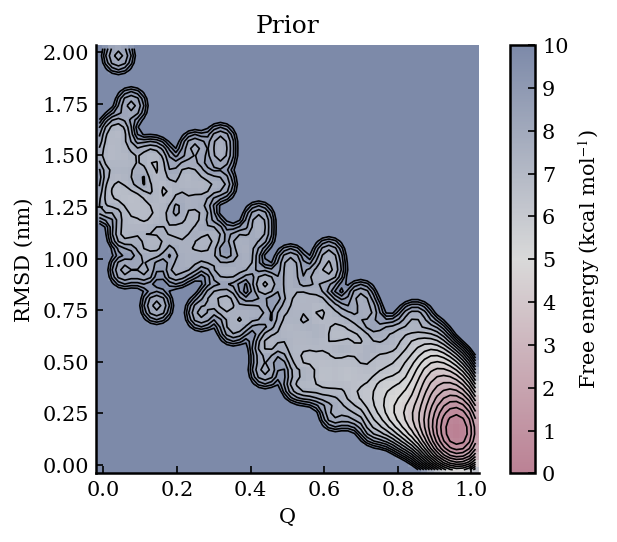

In [12]:
# FEL of posterior 1 (elbow) as a function of Q and RMSD
# with mild Gaussian smoothing of the 2D probability histogram

from matplotlib.colors import LinearSegmentedColormap
from scipy.ndimage import gaussian_filter


protein = proteins[0]
synframes = 0
nbins = 60
max_energy = 10.0   # kcal mol^-1; start with 5.0 or 6.0
sigma = 1.0     # Gaussian smoothing in bin units

# prior weights
wopt = np.load(f'../../{ensemble_master_dir}/{protein}/rewM14DH_scaled/log_lambda_wopt_elbow.npy')
wopt = np.ones(len(wopt))/len(wopt)

# optional: drop synthetic frames at the end if present
Q_use = np.asarray(Q, dtype=float)
rmsd_use = np.asarray(rmsd, dtype=float)
if synframes > 0:
    Q_use = Q_use[:-synframes]
    rmsd_use = rmsd_use[:-synframes]
    wopt = wopt[:-synframes]

# sanity check
assert len(Q_use) == len(rmsd_use) == len(wopt), "Q, rmsd, and wopt must have the same length"

# normalize prior weights
w_post = wopt / np.sum(wopt)

# shared binning
xmin, xmax = np.min(Q_use), np.max(Q_use)
ymin, ymax = np.min(rmsd_use), np.max(rmsd_use)
xpad = 0.02 * (xmax - xmin)
ypad = 0.02 * (ymax - ymin)
xbins = np.linspace(xmin - xpad, xmax + xpad, nbins + 1)
ybins = np.linspace(ymin - ypad, ymax + ypad, nbins + 1)

# weighted 2D histogram
H_post, xedges, yedges = np.histogram2d(Q_use, rmsd_use, bins=[xbins, ybins], weights=w_post)

# smooth histogram for visualization
H_post_smooth = gaussian_filter(H_post, sigma=sigma, mode='constant', cval=0.0)
H_post_smooth = H_post_smooth / np.sum(H_post_smooth)

# convert histogram to FEL
kB = 0.0019872041  # kcal mol^-1 K^-1
T = 303.0

def hist_to_fel(H, kB=0.0019872041, T=293.0):
    F = np.full_like(H, np.nan, dtype=float)
    mask = H > 0
    F[mask] = -kB * T * np.log(H[mask])
    F -= np.nanmin(F)
    return F

F_post = hist_to_fel(H_post_smooth, kB=kB, T=T)

# bin centers for contours
xc = 0.5 * (xedges[:-1] + xedges[1:])
yc = 0.5 * (yedges[:-1] + yedges[1:])
Xc, Yc = np.meshgrid(xc, yc, indexing='ij')

# colour scale: min -> middle -> max_energy
middle = max_energy / 2
cmap = LinearSegmentedColormap.from_list('fel_cmap', [(0.0, "#BB8194"), (0.5, "#D9D9D9"), (1.0, "#7D8AA9")])

# fill any remaining NaNs with max_energy for plotting only
F_plot = np.where(np.isnan(F_post), max_energy, F_post)
F_plot = np.minimum(F_plot, max_energy)

# contour levels
levels = np.arange(0.5, max_energy + 0.001, 0.5)
levels = levels[levels <= np.nanmax(F_post)]

# plotting
fig, ax = plt.subplots(figsize=(4,3.5), constrained_layout=True)

pcm = ax.pcolormesh(xedges, yedges, F_plot.T, shading='auto', cmap=cmap, vmin=0, vmax=max_energy, rasterized=True)
if len(levels) > 0:
    ax.contour(Xc, Yc, F_post, levels=levels, linewidths=0.8, colors='black', rasterized=True)

ax.set_title('Prior')
ax.set_xlabel('Q')
ax.set_ylabel('RMSD (nm)')

ax.tick_params(axis='both', which='both', top=False, right=False)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

cbar = fig.colorbar(pcm, ax=ax, pad=0.02)
cbar.set_label(r'Free energy (kcal mol$^{-1}$)')
cbar.set_ticks(np.arange(0, max_energy + 1, 1))

plt.savefig(outdir+f'{protein}_Q_RMSD_FEL_prior_smoothed.pdf', dpi=300)
plt.show()

/tmp/ipykernel_418814/2132878775.py:114: UserWarning: The following kwargs were not used by contour: 'rasterized'
  ax.contour(Xc, Yc, F_post, levels=levels, linewidths=0.8, colors='black', rasterized=True)


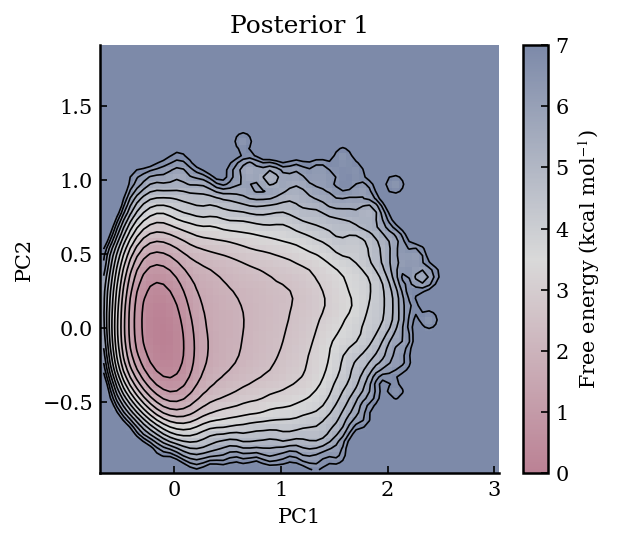

In [14]:
# PCA FEL
# FEL of posterior 1 (elbow) as a function of PC1 and PC2
# PCA coordinates contain all frames, so first sub-index using okframes
# from each trajectory in exactly the same sorted trajectory order

from matplotlib.colors import LinearSegmentedColormap
from scipy.ndimage import gaussian_filter

protein = proteins[0]
synframes = 0
nbins = 60
max_energy = 7.0
sigma = 1.0

# load PCA coordinates for all frames
pca = np.loadtxt(f'../../{ensemble_master_dir}/{protein}/PCA/pca_coordinates.txt')
pc1_all = pca[:,0]
pc2_all = pca[:,1]

# get trajectories in exactly the same order used for PCA/reweighting
trajs = sorted(find_xtc_filenames(f'../../{ensemble_master_dir}/{protein}/'))

# load trajectory frame ranges written by PCA script
frame_info = np.loadtxt(f'../../{ensemble_master_dir}/{protein}/PCA/trajectory_frames.txt', dtype=str)

# build global indices corresponding to okframes from each trajectory
global_okframes = []

for i, traj in enumerate(trajs):
    traj_name = frame_info[i,0]
    start = int(frame_info[i,1])
    end = int(frame_info[i,2])
    n_frames = int(frame_info[i,3])

    assert traj_name == traj, f"Trajectory order mismatch: PCA has {traj_name}, current order has {traj}"

    okframes = np.loadtxt(f'../../{ensemble_master_dir}/{protein}/rewM13DH_scaled/okframes_{traj[:-4]}.txt').astype(int)
    global_okframes.append(start + okframes)

global_okframes = np.concatenate(global_okframes)

# sub-index PCA coordinates to exactly the frames used for reweighting
pc1 = pc1_all[global_okframes]
pc2 = pc2_all[global_okframes]

# posterior 1 weights
wopt = np.load(f'../../{ensemble_master_dir}/{protein}/rewM14DH_scaled/log_lambda_wopt_elbow.npy')

# optional: drop synthetic frames at the end if present
pc1_use = np.asarray(pc1, dtype=float)
pc2_use = np.asarray(pc2, dtype=float)

if synframes > 0:
    pc1_use = pc1_use[:-synframes]
    pc2_use = pc2_use[:-synframes]
    wopt = wopt[:-synframes]

# sanity check
assert len(pc1_use) == len(pc2_use) == len(wopt), f"PC1, PC2, and wopt must have the same length: {len(pc1_use)}, {len(pc2_use)}, {len(wopt)}"

# normalize weights
w_post = wopt / np.sum(wopt)

# shared binning
xmin, xmax = np.min(pc1_use), np.max(pc1_use)
ymin, ymax = np.min(pc2_use), np.max(pc2_use)
xpad = 0.02 * (xmax - xmin)
ypad = 0.02 * (ymax - ymin)
xbins = np.linspace(xmin - xpad, xmax + xpad, nbins + 1)
ybins = np.linspace(ymin - ypad, ymax + ypad, nbins + 1)

# weighted 2D histogram
H_post, xedges, yedges = np.histogram2d(pc1_use, pc2_use, bins=[xbins, ybins], weights=w_post)

# smooth histogram for visualization
H_post_smooth = gaussian_filter(H_post, sigma=sigma, mode='constant', cval=0.0)
H_post_smooth = H_post_smooth / np.sum(H_post_smooth)

# convert histogram to FEL
kB = 0.0019872041
T = 303.0

def hist_to_fel(H, kB=0.0019872041, T=293.0):
    F = np.full_like(H, np.nan, dtype=float)
    mask = H > 0
    F[mask] = -kB * T * np.log(H[mask])
    F -= np.nanmin(F)
    return F

F_post = hist_to_fel(H_post_smooth, kB=kB, T=T)

# bin centers for contours
xc = 0.5 * (xedges[:-1] + xedges[1:])
yc = 0.5 * (yedges[:-1] + yedges[1:])
Xc, Yc = np.meshgrid(xc, yc, indexing='ij')

# colour scale
cmap = LinearSegmentedColormap.from_list('fel_cmap', [(0.0, "#BB8194"), (0.5, "#D9D9D9"), (1.0, "#7D8AA9")])

# fill remaining NaNs with max_energy for plotting only
F_plot = np.where(np.isnan(F_post), max_energy, F_post)
F_plot = np.minimum(F_plot, max_energy)

# contour levels
levels = np.arange(0.5, max_energy + 0.001, 0.5)
levels = levels[levels <= np.nanmax(F_post)]

# plot
fig, ax = plt.subplots(figsize=(4,3.5), constrained_layout=True)

pcm = ax.pcolormesh(xedges, yedges, F_plot.T, shading='auto', cmap=cmap, vmin=0, vmax=max_energy, rasterized=True)

if len(levels) > 0:
    ax.contour(Xc, Yc, F_post, levels=levels, linewidths=0.8, colors='black', rasterized=True)

ax.set_title('Posterior 1')
ax.set_xlabel('PC1')
ax.set_ylabel('PC2')

ax.tick_params(axis='both', which='both', top=False, right=False)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

cbar = fig.colorbar(pcm, ax=ax, pad=0.02)
cbar.set_label(r'Free energy (kcal mol$^{-1}$)')
cbar.set_ticks(np.arange(0, max_energy + 1, 1))

plt.savefig(outdir+f'{protein}_PC1_PC2_FEL_posterior1_smoothed.pdf', dpi=300)
plt.show()

/tmp/ipykernel_418814/3118808795.py:115: UserWarning: The following kwargs were not used by contour: 'rasterized'
  ax.contour(Xc, Yc, F_post, levels=levels, linewidths=0.8, colors='black', rasterized=True)


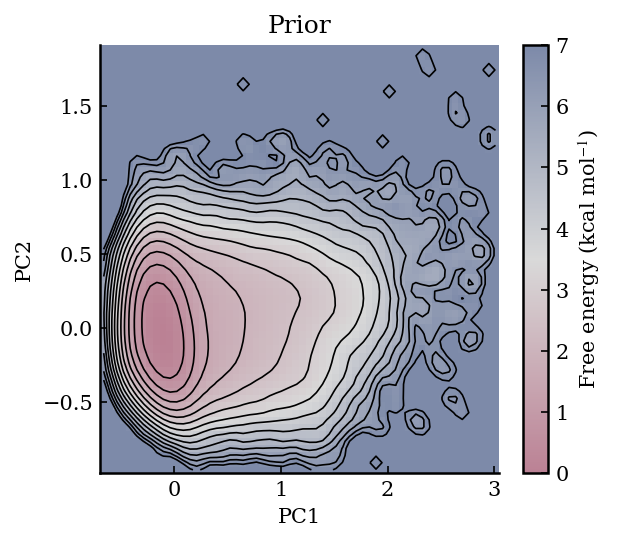

In [15]:
# PCA FEL
# FEL of prior as a function of PC1 and PC2
# PCA coordinates contain all frames, so first sub-index using okframes
# from each trajectory in exactly the same sorted trajectory order

from matplotlib.colors import LinearSegmentedColormap
from scipy.ndimage import gaussian_filter

protein = proteins[0]
synframes = 0
nbins = 60
max_energy = 7.0
sigma = 1.0

# load PCA coordinates for all frames
pca = np.loadtxt(f'../../{ensemble_master_dir}/{protein}/PCA/pca_coordinates.txt')
pc1_all = pca[:,0]
pc2_all = pca[:,1]

# get trajectories in exactly the same order used for PCA/reweighting
trajs = sorted(find_xtc_filenames(f'../../{ensemble_master_dir}/{protein}/'))

# load trajectory frame ranges written by PCA script
frame_info = np.loadtxt(f'../../{ensemble_master_dir}/{protein}/PCA/trajectory_frames.txt', dtype=str)

# build global indices corresponding to okframes from each trajectory
global_okframes = []

for i, traj in enumerate(trajs):
    traj_name = frame_info[i,0]
    start = int(frame_info[i,1])
    end = int(frame_info[i,2])
    n_frames = int(frame_info[i,3])

    assert traj_name == traj, f"Trajectory order mismatch: PCA has {traj_name}, current order has {traj}"

    okframes = np.loadtxt(f'../../{ensemble_master_dir}/{protein}/rewM13DH_scaled/okframes_{traj[:-4]}.txt').astype(int)
    global_okframes.append(start + okframes)

global_okframes = np.concatenate(global_okframes)

# sub-index PCA coordinates to exactly the frames used for reweighting
pc1 = pc1_all[global_okframes]
pc2 = pc2_all[global_okframes]

# prior weights
wopt = np.load(f'../../{ensemble_master_dir}/{protein}/rewM14DH_scaled/log_lambda_wopt_elbow.npy')
wopt = np.ones(wopt.shape[0])/wopt.shape[0]

# optional: drop synthetic frames at the end if present
pc1_use = np.asarray(pc1, dtype=float)
pc2_use = np.asarray(pc2, dtype=float)

if synframes > 0:
    pc1_use = pc1_use[:-synframes]
    pc2_use = pc2_use[:-synframes]
    wopt = wopt[:-synframes]

# sanity check
assert len(pc1_use) == len(pc2_use) == len(wopt), f"PC1, PC2, and wopt must have the same length: {len(pc1_use)}, {len(pc2_use)}, {len(wopt)}"

# normalize weights
w_post = wopt / np.sum(wopt)

# shared binning
xmin, xmax = np.min(pc1_use), np.max(pc1_use)
ymin, ymax = np.min(pc2_use), np.max(pc2_use)
xpad = 0.02 * (xmax - xmin)
ypad = 0.02 * (ymax - ymin)
xbins = np.linspace(xmin - xpad, xmax + xpad, nbins + 1)
ybins = np.linspace(ymin - ypad, ymax + ypad, nbins + 1)

# weighted 2D histogram
H_post, xedges, yedges = np.histogram2d(pc1_use, pc2_use, bins=[xbins, ybins], weights=w_post)

# smooth histogram for visualization
H_post_smooth = gaussian_filter(H_post, sigma=sigma, mode='constant', cval=0.0)
H_post_smooth = H_post_smooth / np.sum(H_post_smooth)

# convert histogram to FEL
kB = 0.0019872041
T = 303.0

def hist_to_fel(H, kB=0.0019872041, T=293.0):
    F = np.full_like(H, np.nan, dtype=float)
    mask = H > 0
    F[mask] = -kB * T * np.log(H[mask])
    F -= np.nanmin(F)
    return F

F_post = hist_to_fel(H_post_smooth, kB=kB, T=T)

# bin centers for contours
xc = 0.5 * (xedges[:-1] + xedges[1:])
yc = 0.5 * (yedges[:-1] + yedges[1:])
Xc, Yc = np.meshgrid(xc, yc, indexing='ij')

# colour scale
cmap = LinearSegmentedColormap.from_list('fel_cmap', [(0.0, "#BB8194"), (0.5, "#D9D9D9"), (1.0, "#7D8AA9")])

# fill remaining NaNs with max_energy for plotting only
F_plot = np.where(np.isnan(F_post), max_energy, F_post)
F_plot = np.minimum(F_plot, max_energy)

# contour levels
levels = np.arange(0.5, max_energy + 0.001, 0.5)
levels = levels[levels <= np.nanmax(F_post)]

# plot
fig, ax = plt.subplots(figsize=(4,3.5), constrained_layout=True)

pcm = ax.pcolormesh(xedges, yedges, F_plot.T, shading='auto', cmap=cmap, vmin=0, vmax=max_energy, rasterized=True)

if len(levels) > 0:
    ax.contour(Xc, Yc, F_post, levels=levels, linewidths=0.8, colors='black', rasterized=True)

ax.set_title('Prior')
ax.set_xlabel('PC1')
ax.set_ylabel('PC2')

ax.tick_params(axis='both', which='both', top=False, right=False)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

cbar = fig.colorbar(pcm, ax=ax, pad=0.02)
cbar.set_label(r'Free energy (kcal mol$^{-1}$)')
cbar.set_ticks(np.arange(0, max_energy + 1, 1))

plt.savefig(outdir+f'{protein}_PC1_PC2_FEL_prior_smoothed.pdf', dpi=300)
plt.show()

/tmp/ipykernel_418814/2154912777.py:126: UserWarning: The following kwargs were not used by contour: 'rasterized'
  ax.contour(Xc, Yc, F_post, levels=levels, linewidths=0.8, colors='black', rasterized=True)


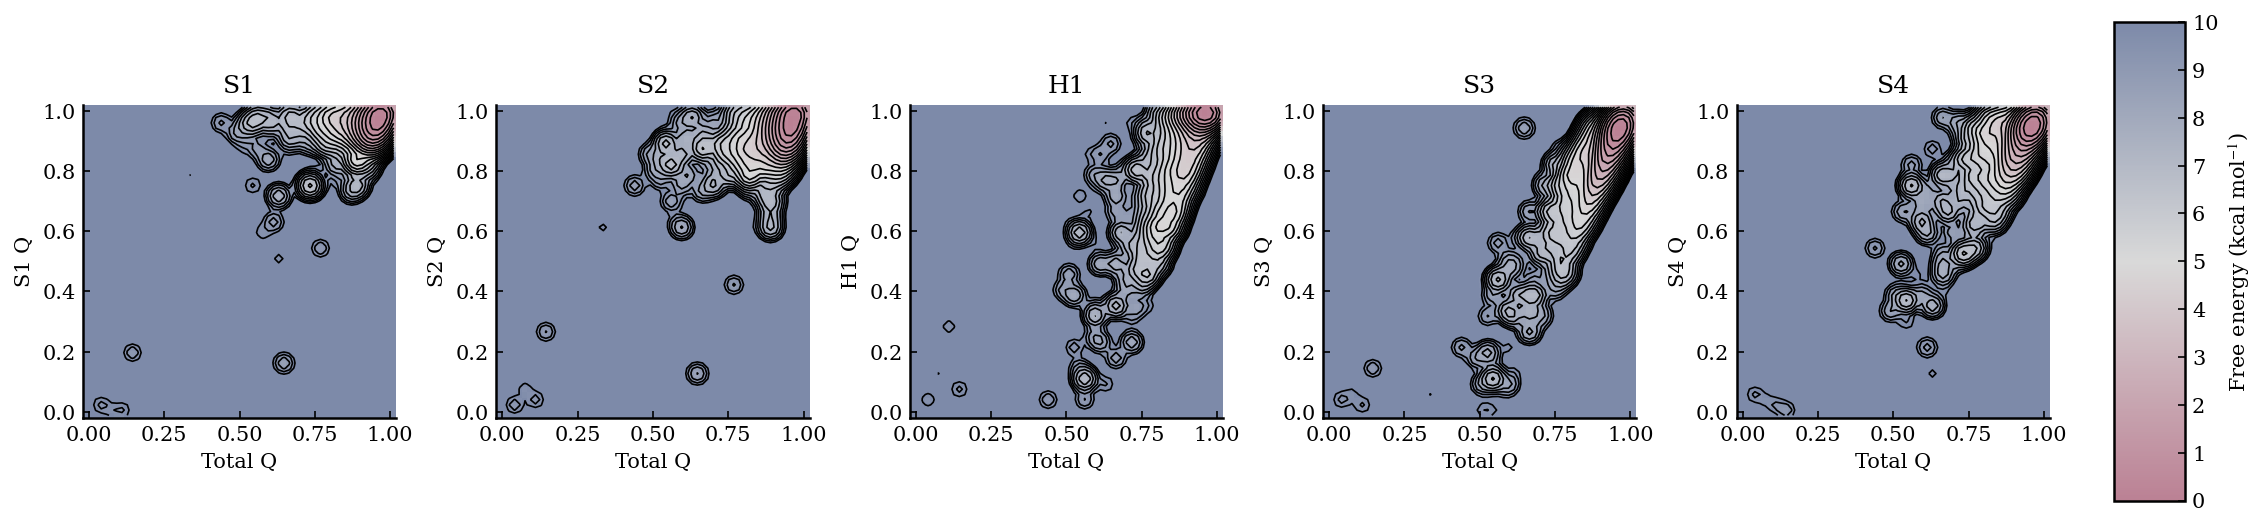

In [18]:
# FEL of posterior 1 (elbow) as a function of total Q
# and Q of strands s1-s4 and helix h1, with mild Gaussian smoothing
# Q values are first filtered using the same per-trajectory okframes
# used for reweighting so that they correspond exactly to wopt

from matplotlib.colors import LinearSegmentedColormap
from scipy.ndimage import gaussian_filter

ensemble_master_dir2 = 'BIOEMU_DATA'

protein = proteins[0]
helices = ['s1', 's2', 'h1', 's3', 's4']
synframes = 0
nbins = 60
max_energy = 10.0      # kcal mol^-1
sigma = 1.0           # Gaussian smoothing in bin units

# load total Q and helix Q values in the same trajectory order
trajs = sorted(find_xtc_filenames(f'../../{ensemble_master_dir2}/{protein}/'))

Q_total = []
Q_helices = {helix: [] for helix in helices}

for traj in trajs:
    idx = traj[4:-4]

    tmp_Q_total = np.loadtxt(f'../../{ensemble_master_dir2}/{protein}/native_contacts/Q{idx}.txt')

    tmp_Q_helices = {}
    for helix in helices:
        tmp_Q_helices[helix] = np.loadtxt(f'../../{ensemble_master_dir2}/{protein}/native_contacts_{helix}/Q{idx}.txt')

    okframes = np.loadtxt(f'../../{ensemble_master_dir2}/{protein}/rewM13DH_scaled/okframes_{traj[:-4]}.txt').astype(int)
    okframes = np.atleast_1d(okframes)

    Q_total.append(np.asarray(tmp_Q_total).ravel()[okframes])

    for helix in helices:
        Q_helices[helix].append(np.asarray(tmp_Q_helices[helix]).ravel()[okframes])

Q_total = np.concatenate(Q_total)

for helix in helices:
    Q_helices[helix] = np.concatenate(Q_helices[helix])

# posterior 1 weights
wopt = np.load(f'../../{ensemble_master_dir2}/{protein}/rewM14DH_scaled/log_lambda_wopt_elbow.npy')

# optional: drop synthetic frames at the end if present
Q_total_use = np.asarray(Q_total, dtype=float)
Q_helices_use = {helix: np.asarray(Q_helices[helix], dtype=float) for helix in helices}

if synframes > 0:
    Q_total_use = Q_total_use[:-synframes]
    for helix in helices:
        Q_helices_use[helix] = Q_helices_use[helix][:-synframes]
    wopt = wopt[:-synframes]

# sanity checks
for helix in helices:
    assert len(Q_total_use) == len(Q_helices_use[helix]) == len(wopt), f"Total Q, {helix} Q, and wopt must have the same length: {len(Q_total_use)}, {len(Q_helices_use[helix])}, {len(wopt)}"

# normalize posterior weights
w_post = wopt / np.sum(wopt)

# total-Q binning shared by all panels
xmin, xmax = np.min(Q_total_use), np.max(Q_total_use)
xpad = 0.02 * (xmax - xmin)
xbins = np.linspace(xmin - xpad, xmax + xpad, nbins + 1)

# thermodynamic constants
kB = 0.0019872041  # kcal mol^-1 K^-1
T = 303.0

def hist_to_fel(H, kB=0.0019872041, T=293.0):
    F = np.full_like(H, np.nan, dtype=float)
    mask = H > 0
    F[mask] = -kB * T * np.log(H[mask])
    F -= np.nanmin(F)
    return F

# colour scale
cmap = LinearSegmentedColormap.from_list('fel_cmap', [(0.0, "#BB8194"), (0.5, "#D9D9D9"), (1.0, "#7D8AA9")])

# plot
fig, axes = plt.subplots(1, 5, figsize=(15.0, 3.4), constrained_layout=True)

pcm = None

for ax, helix in zip(axes, helices):

    Q_helix_use = Q_helices_use[helix]

    # helix-specific y binning
    ymin, ymax = np.min(Q_helix_use), np.max(Q_helix_use)
    ypad = 0.02 * (ymax - ymin)
    ybins = np.linspace(ymin - ypad, ymax + ypad, nbins + 1)

    # weighted 2D histogram
    H_post, xedges, yedges = np.histogram2d(Q_total_use, Q_helix_use, bins=[xbins, ybins], weights=w_post)

    # smooth histogram
    H_post_smooth = gaussian_filter(H_post, sigma=sigma, mode='constant', cval=0.0)
    H_post_smooth = H_post_smooth / np.sum(H_post_smooth)

    # convert histogram to FEL
    F_post = hist_to_fel(H_post_smooth, kB=kB, T=T)

    # bin centers for contours
    xc = 0.5 * (xedges[:-1] + xedges[1:])
    yc = 0.5 * (yedges[:-1] + yedges[1:])
    Xc, Yc = np.meshgrid(xc, yc, indexing='ij')

    # fill remaining NaNs with max_energy for plotting only
    F_plot = np.where(np.isnan(F_post), max_energy, F_post)
    F_plot = np.minimum(F_plot, max_energy)

    # contour levels
    levels = np.arange(0.5, max_energy + 0.001, 0.5)
    levels = levels[levels <= np.nanmax(F_post)]

    # FEL
    pcm = ax.pcolormesh(xedges, yedges, F_plot.T, shading='auto', cmap=cmap, vmin=0, vmax=max_energy, rasterized=True)

    if len(levels) > 0:
        ax.contour(Xc, Yc, F_post, levels=levels, linewidths=0.8, colors='black', rasterized=True)

    ax.set_title(helix.upper())
    ax.set_xlabel('Total Q')
    ax.set_ylabel(f'{helix.upper()} Q')

    ax.set_box_aspect(1)

    ax.tick_params(axis='both', which='both', top=False, right=False)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

# single shared, thinner colourbar
cbar = fig.colorbar(pcm, ax=axes, pad=0.02, fraction=0.025, aspect=30)
cbar.set_label(r'Free energy (kcal mol$^{-1}$)')
cbar.set_ticks(np.arange(0, max_energy + 1, 1))

plt.savefig(outdir+f'{protein}_Q_h1-h4_Q_FEL_posterior1_smoothed_{ensemble_master_dir2}.pdf', dpi=300)
plt.show()

/tmp/ipykernel_418814/3047478243.py:126: UserWarning: The following kwargs were not used by contour: 'rasterized'
  ax.contour(Xc, Yc, F_post, levels=levels, linewidths=0.8, colors='black', rasterized=True)


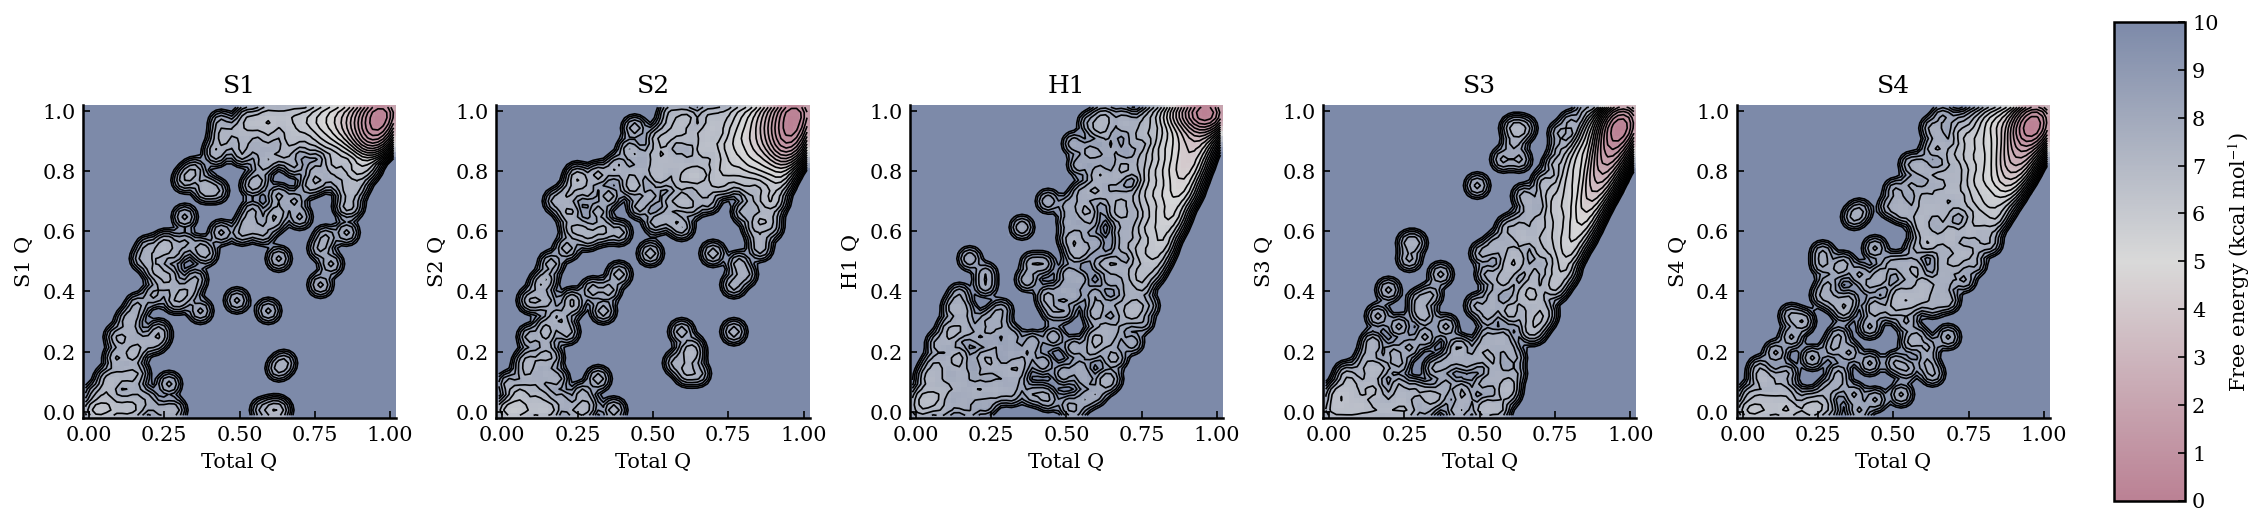

In [19]:
# FEL of prior as a function of total Q
# and Q of strands s1-s4 and helix h1, with mild Gaussian smoothing
# Q values are first filtered using the same per-trajectory okframes
# used for reweighting so that they correspond exactly to wopt

from matplotlib.colors import LinearSegmentedColormap
from scipy.ndimage import gaussian_filter

ensemble_master_dir2 = 'BIOEMU_DATA'

protein = proteins[0]
helices = ['s1', 's2', 'h1', 's3', 's4']
synframes = 0
nbins = 60
max_energy = 10.0      # kcal mol^-1
sigma = 1.0           # Gaussian smoothing in bin units

# load total Q and helix Q values in the same trajectory order
trajs = sorted(find_xtc_filenames(f'../../{ensemble_master_dir2}/{protein}/'))

Q_total = []
Q_helices = {helix: [] for helix in helices}

for traj in trajs:
    idx = traj[4:-4]

    tmp_Q_total = np.loadtxt(f'../../{ensemble_master_dir2}/{protein}/native_contacts/Q{idx}.txt')

    tmp_Q_helices = {}
    for helix in helices:
        tmp_Q_helices[helix] = np.loadtxt(f'../../{ensemble_master_dir2}/{protein}/native_contacts_{helix}/Q{idx}.txt')

    okframes = np.loadtxt(f'../../{ensemble_master_dir2}/{protein}/rewM13DH_scaled/okframes_{traj[:-4]}.txt').astype(int)
    okframes = np.atleast_1d(okframes)

    Q_total.append(np.asarray(tmp_Q_total).ravel()[okframes])

    for helix in helices:
        Q_helices[helix].append(np.asarray(tmp_Q_helices[helix]).ravel()[okframes])

Q_total = np.concatenate(Q_total)

for helix in helices:
    Q_helices[helix] = np.concatenate(Q_helices[helix])

# prior weights
wopt = np.ones(Q_total.shape[0])/Q_total.shape[0]

# optional: drop synthetic frames at the end if present
Q_total_use = np.asarray(Q_total, dtype=float)
Q_helices_use = {helix: np.asarray(Q_helices[helix], dtype=float) for helix in helices}

if synframes > 0:
    Q_total_use = Q_total_use[:-synframes]
    for helix in helices:
        Q_helices_use[helix] = Q_helices_use[helix][:-synframes]
    wopt = wopt[:-synframes]

# sanity checks
for helix in helices:
    assert len(Q_total_use) == len(Q_helices_use[helix]) == len(wopt), f"Total Q, {helix} Q, and wopt must have the same length: {len(Q_total_use)}, {len(Q_helices_use[helix])}, {len(wopt)}"

# normalize posterior weights
w_post = wopt / np.sum(wopt)

# total-Q binning shared by all panels
xmin, xmax = np.min(Q_total_use), np.max(Q_total_use)
xpad = 0.02 * (xmax - xmin)
xbins = np.linspace(xmin - xpad, xmax + xpad, nbins + 1)

# thermodynamic constants
kB = 0.0019872041  # kcal mol^-1 K^-1
T = 303.0

def hist_to_fel(H, kB=0.0019872041, T=293.0):
    F = np.full_like(H, np.nan, dtype=float)
    mask = H > 0
    F[mask] = -kB * T * np.log(H[mask])
    F -= np.nanmin(F)
    return F

# colour scale
cmap = LinearSegmentedColormap.from_list('fel_cmap', [(0.0, "#BB8194"), (0.5, "#D9D9D9"), (1.0, "#7D8AA9")])

# plot
fig, axes = plt.subplots(1, 5, figsize=(15.0, 3.4), constrained_layout=True)

pcm = None

for ax, helix in zip(axes, helices):

    Q_helix_use = Q_helices_use[helix]

    # helix-specific y binning
    ymin, ymax = np.min(Q_helix_use), np.max(Q_helix_use)
    ypad = 0.02 * (ymax - ymin)
    ybins = np.linspace(ymin - ypad, ymax + ypad, nbins + 1)

    # weighted 2D histogram
    H_post, xedges, yedges = np.histogram2d(Q_total_use, Q_helix_use, bins=[xbins, ybins], weights=w_post)

    # smooth histogram
    H_post_smooth = gaussian_filter(H_post, sigma=sigma, mode='constant', cval=0.0)
    H_post_smooth = H_post_smooth / np.sum(H_post_smooth)

    # convert histogram to FEL
    F_post = hist_to_fel(H_post_smooth, kB=kB, T=T)

    # bin centers for contours
    xc = 0.5 * (xedges[:-1] + xedges[1:])
    yc = 0.5 * (yedges[:-1] + yedges[1:])
    Xc, Yc = np.meshgrid(xc, yc, indexing='ij')

    # fill remaining NaNs with max_energy for plotting only
    F_plot = np.where(np.isnan(F_post), max_energy, F_post)
    F_plot = np.minimum(F_plot, max_energy)

    # contour levels
    levels = np.arange(0.5, max_energy + 0.001, 0.5)
    levels = levels[levels <= np.nanmax(F_post)]

    # FEL
    pcm = ax.pcolormesh(xedges, yedges, F_plot.T, shading='auto', cmap=cmap, vmin=0, vmax=max_energy, rasterized=True)

    if len(levels) > 0:
        ax.contour(Xc, Yc, F_post, levels=levels, linewidths=0.8, colors='black', rasterized=True)

    ax.set_title(helix.upper())
    ax.set_xlabel('Total Q')
    ax.set_ylabel(f'{helix.upper()} Q')

    ax.set_box_aspect(1)

    ax.tick_params(axis='both', which='both', top=False, right=False)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

# single shared, thinner colourbar
cbar = fig.colorbar(pcm, ax=axes, pad=0.02, fraction=0.025, aspect=30)
cbar.set_label(r'Free energy (kcal mol$^{-1}$)')
cbar.set_ticks(np.arange(0, max_energy + 1, 1))

plt.savefig(outdir+f'{protein}_Q_h1-h4_Q_FEL_prior_smoothed_{ensemble_master_dir2}.pdf', dpi=300)
plt.show()

In [ ]:
# too noisy